#Logistic Regression (Loan Approval Prediction)

**Q1. Data Loading & Understanding**

**a) Load the dataset into Python.**

**b) Display the first 5 rows.**

**c) Check the shape of the dataset.**

**d) Display the data types of each column.**


In [7]:
import pandas as pd

# a) Load the dataset into Python
df = pd.read_csv("loan_approval - loan_approval.csv")

# b) Display the first 5 rows
print("First 5 Rows:")
display(df.head())

# c) Check the shape of the dataset
print("Shape of Dataset:", df.shape)

# d) Display the data types of each column
print("Data Types of Each Column:")
print(df.dtypes)

First 5 Rows:


,name,city,income,credit_score,loan_amount,years_employed,points,loan_approved
0,Allison Hill,East Jill,113810,389,39698,27,50,False
1,Brandon Hall,New Jamesside,44592,729,15446,28,55,False
2,Rhonda Smith,Lake Roberto,33278,584,11189,13,45,False
3,Gabrielle Davis,West Melanieview,127196,344,48823,29,50,False
4,Valerie Gray,Mariastad,66048,496,47174,4,25,False


Shape of Dataset: (2000, 8)
Data Types of Each Column:
name              object
city              object
income             int64
credit_score       int64
loan_amount        int64
years_employed     int64
points             int64
loan_approved       bool
dtype: object


**Q2. Data Cleaning**

**a) Check for missing values in the dataset.**

**b) Handle missing values appropriately.**

**c) Identify categorical columns present in the dataset.**

In [4]:
# a) Check for missing values
print("Missing Values in Each Column:")
print(df.isnull().sum())

# Check total missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())


# b) Handle missing values appropriately
# Fill missing numerical values with the median
num_cols = df.select_dtypes(include=['int64', 'float64']).columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values with the mode
cat_cols = df.select_dtypes(include=['object', 'bool', 'category']).columns

for col in cat_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())


# c) Identify categorical columns
print("\nCategorical Columns:")
print(df.select_dtypes(include=['object', 'bool', 'category']).columns.tolist())

Missing Values in Each Column:
name              0
city              0
income            0
credit_score      0
loan_amount       0
years_employed    0
points            0
loan_approved     0
dtype: int64

Total Missing Values: 0

Missing Values After Cleaning:
name              0
city              0
income            0
credit_score      0
loan_amount       0
years_employed    0
points            0
loan_approved     0
dtype: int64

Categorical Columns:
['name', 'city', 'loan_approved']


**Q3. Exploratory Data Analysis (EDA)**

**a) Plot the distribution of the target variable.**


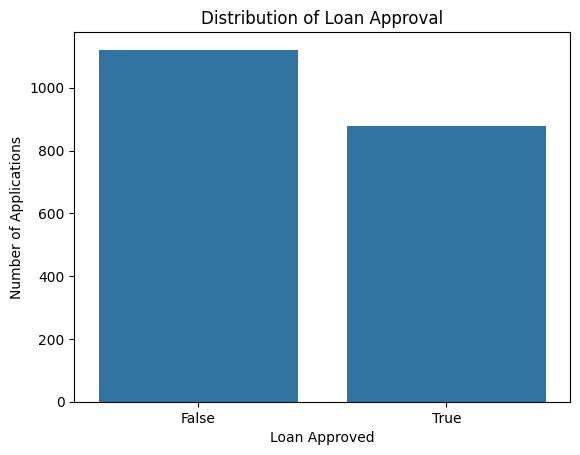

loan_approved
False    1121
True      879
Name: count, dtype: int64


In [9]:
# Plot the distribution of loan approval

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.countplot(data=df, x='loan_approved')

plt.title('Distribution of Loan Approval')
plt.xlabel('Loan Approved')
plt.ylabel('Number of Applications')
plt.show()

# Display counts
print(df['loan_approved'].value_counts())

 - This chart shows the number of loan applications that were approved 879 (True) and not approved 1121 (False). It helps us understand whether the target variable is balanced or imbalanced.

**b) Analyze the relationship between one numerical feature and the target variable.**

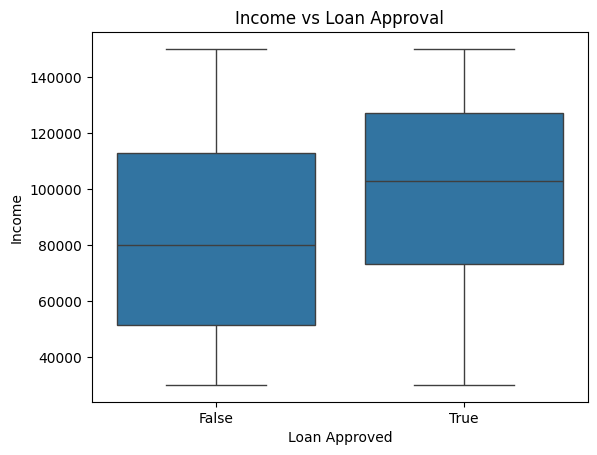

loan_approved
False    83317.456735
True     99855.614334
Name: income, dtype: float64


In [10]:
# Compare income by loan approval status
sns.boxplot(data=df, x='loan_approved', y='income')

plt.title('Income vs Loan Approval')
plt.xlabel('Loan Approved')
plt.ylabel('Income')
plt.show()

# Calculate average income for each group
print(df.groupby('loan_approved')['income'].mean())

 - The boxplot compares the income of approved and rejected applicants. If the approved group has a higher median income, it may indicate that income is associated with loan approval.

**c) Analyze the relationship between Years of Employment and the target variable.**

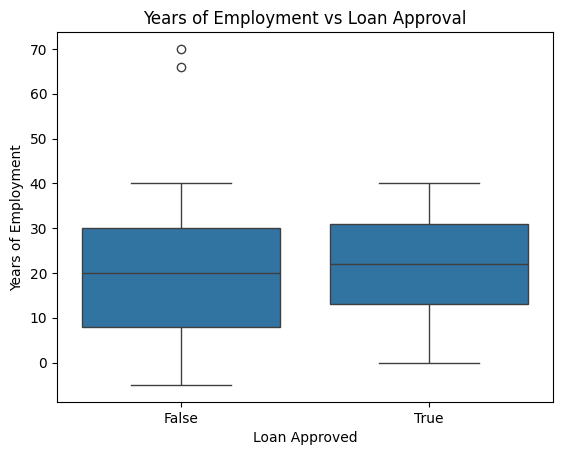

loan_approved
False    19.425513
True     21.829352
Name: years_employed, dtype: float64


In [11]:
# Compare years of employment by loan approval status
sns.boxplot(data=df, x='loan_approved', y='years_employed')

plt.title('Years of Employment vs Loan Approval')
plt.xlabel('Loan Approved')
plt.ylabel('Years of Employment')
plt.show()

# Calculate average years of employment for each group
print(df.groupby('loan_approved')['years_employed'].mean())

This chart compares the years of employment for approved and rejected applicants. If approved applicants have a higher median or average number of employment years, it may suggest a relationship between employment stability and loan approval.

**Q4. Outlier Detection and Treatment**

**a) Detect outliers in numerical columns using the IQR method.**

In [12]:
# Select numerical columns
num_cols = df.select_dtypes(include=['int64', 'float64']).columns

# Detect outliers using IQR
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_limit) | (df[col] > upper_limit)]

    print(f"{col}: {len(outliers)} outliers")

income: 0 outliers
credit_score: 3 outliers
loan_amount: 0 outliers
years_employed: 2 outliers
points: 0 outliers


**b) Treat outliers using capping techniques.**


In [13]:
# Cap outliers using IQR lower and upper limits
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    df[col] = df[col].clip(lower=lower_limit, upper=upper_limit)

print("Outliers have been capped successfully.")

Outliers have been capped successfully.


**Q5. Convert target variables into numerical format suitable for model building and drop unnecessary
columns.**

In [14]:
# Convert target variable into numerical format
df['loan_approved'] = df['loan_approved'].astype(int)

# Drop unnecessary columns
df = df.drop(columns=['name', 'city'])

# Display first 5 rows
display(df.head())

# Check data types
print(df.dtypes)

,income,credit_score,loan_amount,years_employed,points,loan_approved
0,113810,389.0,39698,27.0,50,0
1,44592,729.0,15446,28.0,55,0
2,33278,584.0,11189,13.0,45,0
3,127196,344.0,48823,29.0,50,0
4,66048,496.0,47174,4.0,25,0


income              int64
credit_score      float64
loan_amount         int64
years_employed    float64
points              int64
loan_approved       int64
dtype: object


**Q6. Feature Selection and Data Splitting**

**a) Separate independent variables (X) and dependent variable (y).**


In [15]:
# Separate independent variables (X) and dependent variable (y)
X = df.drop('loan_approved', axis=1)
y = df['loan_approved']

print("Independent Variables (X):")
display(X.head())

print("Dependent Variable (y):")
display(y.head())

Independent Variables (X):


,income,credit_score,loan_amount,years_employed,points
0,113810,389.0,39698,27.0,50
1,44592,729.0,15446,28.0,55
2,33278,584.0,11189,13.0,45
3,127196,344.0,48823,29.0,50
4,66048,496.0,47174,4.0,25


Dependent Variable (y):


,loan_approved
0,0
1,0
2,0
3,0
4,0


**b) Split the dataset into training and testing sets.**

In [16]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (1600, 5)
Testing data shape: (400, 5)


**Q7. Apply feature scaling to the dataset using StandardScaler.**

In [17]:
from sklearn.preprocessing import StandardScaler

# Create StandardScaler object
scaler = StandardScaler()

# Fit and transform training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data
X_test_scaled = scaler.transform(X_test)

print("Scaled Training Data:")
print(X_train_scaled[:5])

print("\nScaled Testing Data:")
print(X_test_scaled[:5])

Scaled Training Data:
[[-0.17342933  0.47850982  0.03478074 -1.14858773 -0.1017349 ]
 [-0.22960205  0.77983528 -1.22829888  1.3855275   1.25699495]
 [ 0.4646404  -0.56075553  0.36246017  1.46999801 -0.37348087]
 [-0.76117645  1.02581524 -0.84514756  1.3855275   1.25699495]
 [ 1.06164292  1.65306415 -1.23690902 -0.30388265  2.34397883]]

Scaled Testing Data:
[[ 0.2652709   0.49080882  1.53485099 -0.13494164  0.17001107]
 [-0.82168583 -0.67144651  0.09265219  0.37188141 -1.18871878]
 [-1.57937726  1.61616716 -0.69390547 -0.8107057   0.44175704]
 [ 0.42595981  0.75523728  0.49556449  1.21658649  0.98524898]
 [-1.0786251  -0.15488859  1.53223972  1.21658649 -1.18871878]]


**Q8. Logistic Regression Model Building**

**a) Train a Logistic Regression model.**


In [18]:
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model
model = LogisticRegression()

# Train the model
model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


**b) Predict the output for test data.**

In [19]:
# Predict loan approval for test data
y_pred = model.predict(X_test_scaled)

# Display actual and predicted values
results = pd.DataFrame({
    'Actual Loan Approval': y_test.values,
    'Predicted Loan Approval': y_pred
})

print(results.head(10))

   Actual Loan Approval  Predicted Loan Approval
0                     1                        1
1                     0                        0
2                     1                        1
3                     1                        1
4                     0                        0
5                     1                        1
6                     0                        0
7                     1                        1
8                     0                        0
9                     0                        0


**Q9. Model Evaluation – Confusion Matrix**

**a) Generate the confusion matrix.**


Confusion Matrix:
[[224   0]
 [  0 176]]


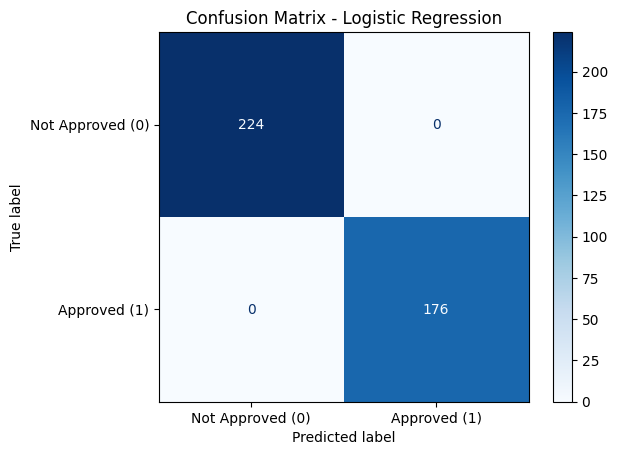

In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Not Approved (0)', 'Approved (1)']
)

disp.plot(cmap='Blues')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

**b) Interpret the results.**

\begin{bmatrix}
224 & 0\\
0 & 176
\end{bmatrix}

 - True Negative (224): The model correctly predicted 224 loan applications as not approved.

 - False Positive (0): The model incorrectly predicted zero rejected loan applications as approved.

 - False Negative (0): The model incorrectly predicted zero approved loan applications as not approved.

 - True Positive (176): The model correctly predicted 176 loan applications as approved.

 - The Logistic Regression model correctly classified all 400 test records, with no false predictions. It achieved 100% accuracy on this test set.

**Q10. Model Evaluation – ROC Curve & AUC**

**a) Plot the ROC curve.**


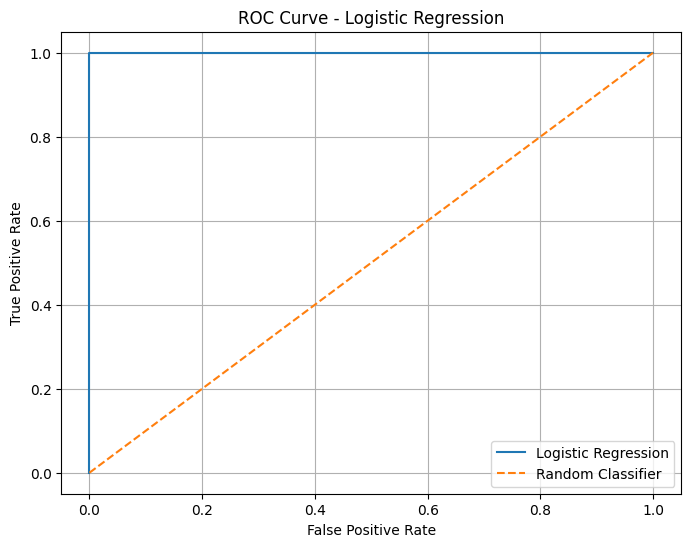

In [21]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Calculate predicted probabilities
y_prob = model.predict_proba(X_test_scaled)[:, 1]

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label='Logistic Regression')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.title('ROC Curve - Logistic Regression')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.grid(True)
plt.show()

**b) Calculate the AUC score.**

In [22]:
# Calculate AUC score
auc_score = roc_auc_score(y_test, y_prob)

print("AUC Score:", auc_score)

AUC Score: 1.0


 - The Logistic Regression model achieved an AUC score of 1.0, which indicates perfect separation between approved and not-approved loan applications on the test dataset. The ROC curve demonstrates that the model can distinguish between the two classes very effectively.

 $$
 ***
 $$